# Notebook 04 — Modelagem: PLSR e Random Forest

Divide calibração e validação (estratificada pelos grupos), escolhe o tratamento e o número de
variáveis latentes do PLSR por validação cruzada, ajusta um Random Forest sobre escores de PCA,
compara as métricas e salva o modelo com os limites do domínio de aplicação.

**Entradas:** `espectros_pp.npz`, `df_pp.pkl`, `dados_brutos.npz` · **Saídas:** `modelo_solo.joblib`, `metricas.csv`, `predicoes_validacao.csv`, figuras `04_*.png`

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import config as cfg, utils

cfg.PASTA_FIG.mkdir(parents=True, exist_ok=True)
import joblib
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline

d = np.load(cfg.PASTA / 'espectros_pp.npz')
X_suav, X_d1, X_snv, y, wl = d['X_suav'], d['X_d1'], d['X_snv'], d['y'], d['wl']
df = pd.read_pickle(cfg.PASTA / 'df_pp.pkl')
wl_orig = np.load(cfg.PASTA / 'dados_brutos.npz')['wl_orig']
n = len(y)

## 1. Divisão calibração/validação

In [2]:
idx_tr, idx_te = train_test_split(np.arange(n), test_size=cfg.TEST_SIZE, random_state=cfg.SEED,
                                  stratify=df['cluster'])
ytr, yte = y[idx_tr], y[idx_te]
print(f'Calibração: {len(idx_tr)} | Validação: {len(idx_te)}')

Calibração: 590 | Validação: 254


## 2. Comparação de tratamentos (RMSECV do PLSR)

,melhor_nLV,RMSECV
sg,2,2.71
d1,1,2.87
snv,1,2.74


Tratamento escolhido: sg


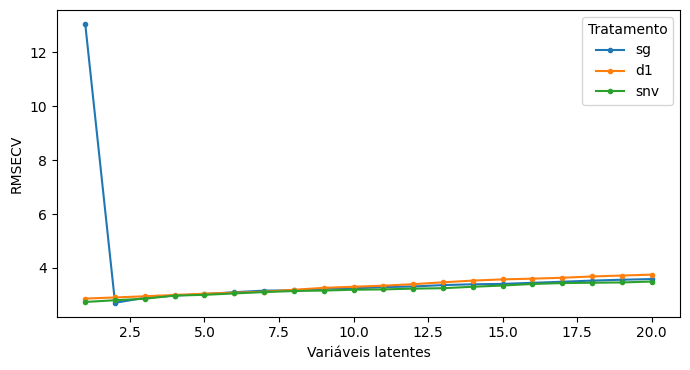

In [3]:
TRATS = {'sg': X_suav, 'd1': X_d1, 'snv': X_snv}
cv = KFold(cfg.CV_FOLDS, shuffle=True, random_state=cfg.SEED)

def rmsecv(X, alvo, max_lv=cfg.MAX_LV):
    return np.array([np.sqrt(mean_squared_error(alvo, cross_val_predict(PLSRegression(k), X, alvo, cv=cv).ravel()))
                     for k in range(1, max_lv + 1)])

curvas = {t: rmsecv(TRATS[t][idx_tr], ytr) for t in cfg.TRATAMENTOS}
resumo = pd.DataFrame({'melhor_nLV': {t: int(c.argmin()) + 1 for t, c in curvas.items()},
                       'RMSECV': {t: c.min() for t, c in curvas.items()}}).round(2)
display(resumo)

TRAT_FINAL = cfg.TRATAMENTO_FIXO or resumo['RMSECV'].idxmin()
print('Tratamento escolhido:', TRAT_FINAL)

fig, ax = plt.subplots(figsize=(7, 3.8))
for t, c in curvas.items():
    ax.plot(range(1, cfg.MAX_LV + 1), c, 'o-', ms=3, label=t)
ax.set_xlabel('Variáveis latentes'); ax.set_ylabel('RMSECV'); ax.legend(title='Tratamento')
plt.tight_layout(); utils.salva_figura(fig, '04_rmsecv_plsr.png'); plt.show()

## 3. PLSR final

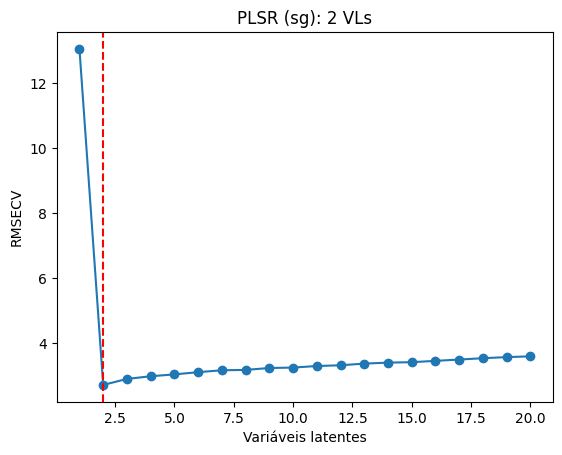

In [4]:
curva = curvas[TRAT_FINAL]
nlv = int(curva.argmin()) + 1
Xtr, Xte = TRATS[TRAT_FINAL][idx_tr], TRATS[TRAT_FINAL][idx_te]

pls = PLSRegression(n_components=nlv).fit(Xtr, ytr)
pred_pls_cal = pls.predict(Xtr).ravel()
pred_pls_cv = cross_val_predict(PLSRegression(nlv), Xtr, ytr, cv=cv).ravel()
pred_pls_val = pls.predict(Xte).ravel()

plt.plot(range(1, cfg.MAX_LV + 1), curva, 'o-')
plt.axvline(nlv, color='red', ls='--')
plt.xlabel('Variáveis latentes'); plt.ylabel('RMSECV'); plt.title(f'PLSR ({TRAT_FINAL}): {nlv} VLs')
plt.show()

## 4. Random Forest sobre escores de PCA

In [5]:
rf_pipe = Pipeline([('pca', PCA()),
                    ('rf', RandomForestRegressor(n_estimators=cfg.N_ARVORES, random_state=cfg.SEED, n_jobs=-1))])
if cfg.BUSCA_RF:
    grade = {'pca__n_components': [10, 20, 30],
             'rf__max_features': ['sqrt', 0.3, 1.0],
             'rf__min_samples_leaf': [1, 2, 5]}
    busca = RandomizedSearchCV(rf_pipe, grade, n_iter=cfg.N_ITER_BUSCA, cv=5, random_state=cfg.SEED,
                               scoring='neg_root_mean_squared_error', n_jobs=-1).fit(Xtr, ytr)
    rf = busca.best_estimator_
    print('Melhores parâmetros:', busca.best_params_)
    print(f'RMSECV (5 partições): {-busca.best_score_:.2f}')
else:
    rf = rf_pipe.set_params(pca__n_components=cfg.N_PCS_RF).fit(Xtr, ytr)

pred_rf_cal = rf.predict(Xtr)
pred_rf_val = rf.predict(Xte)

Melhores parâmetros: {'rf__min_samples_leaf': 5, 'rf__max_features': 1.0, 'pca__n_components': 10}
RMSECV (5 partições): 2.99


## 5. Tabela de métricas

In [6]:
linhas = {('PLSR', 'Calibração'): utils.avalia(ytr, pred_pls_cal),
          ('PLSR', 'Validação cruzada'): utils.avalia(ytr, pred_pls_cv),
          ('PLSR', 'Validação'): utils.avalia(yte, pred_pls_val),
          ('Random Forest', 'Calibração'): utils.avalia(ytr, pred_rf_cal),
          ('Random Forest', 'Validação'): utils.avalia(yte, pred_rf_val)}
metricas = pd.DataFrame(linhas).T
metricas.index.names = ['Modelo', 'Conjunto']
display(metricas.round(3))

R2   RMSE     RPD    RPIQ   Viés
Modelo        Conjunto                                              
PLSR          Calibração         0.983  2.693   7.642  12.229 -0.000
              Validação cruzada  0.983  2.710   7.597  12.156 -0.002
              Validação          0.982  2.991   7.410  11.067 -0.200
Random Forest Calibração         0.992  1.851  11.121  17.795 -0.004
              Validação          0.970  3.853   5.751   8.590 -0.569

## 6. Domínio de aplicação e salvamento

In [7]:
pca_dom = PCA(n_components=cfg.N_PCS_DOMINIO).fit(Xtr)
t2_cal, q_cal = utils.t2_q(pca_dom, Xtr)
lim_t2 = float(np.percentile(t2_cal, cfg.PERC_DOMINIO))
lim_q = float(np.percentile(q_cal, cfg.PERC_DOMINIO))
print(f'Limites do domínio (percentil {cfg.PERC_DOMINIO} da calibração): T² = {lim_t2:.1f} | Q = {lim_q:.4f}')

modelo = {'pls': pls, 'rf': rf, 'pca': rf.named_steps['pca'], 'nlv': nlv, 'tratamento': TRAT_FINAL,
          'alvo': cfg.COL_ALVO, 'wl': wl_orig, 'wl_orig': wl_orig, 'wl_pp': wl,
          'pca_dom': pca_dom, 'lim_t2': lim_t2, 'lim_q': lim_q, 'escores_cal': pca_dom.transform(Xtr),
          't2_cal': t2_cal, 'q_cal': q_cal}
joblib.dump(modelo, cfg.PASTA / 'modelo_solo.joblib')
metricas.to_csv(cfg.PASTA / 'metricas.csv')
pd.DataFrame({'id': df['id'].to_numpy()[idx_te], 'cluster': df['cluster'].to_numpy()[idx_te],
              'observado': yte, 'pred_PLSR': pred_pls_val, 'pred_RF': pred_rf_val}
             ).to_csv(cfg.PASTA / 'predicoes_validacao.csv', index=False)
print('Salvos: modelo_solo.joblib, metricas.csv e predicoes_validacao.csv')

Limites do domínio (percentil 99 da calibração): T² = 19.9 | Q = 0.0012


Salvos: modelo_solo.joblib, metricas.csv e predicoes_validacao.csv
